[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/hentablihamza/attention-explained/blob/main/notebooks/05_attention_heatmaps.ipynb)

# 05 · Attention Weights as a Heatmap

*Attention, Explained · Hamza Hentabli, Ph.D. · ~25 min*

The most famous picture in deep learning is the **attention heatmap**. In this notebook we build one from real word vectors, learn how to read it, compare it with other visualisations, and see how temperature and projections change what it shows.

**Learning objectives.** By the end of this notebook you will be able to:

- build an **attention matrix** for a real sentence and draw it as a **heatmap**
- read rows/columns correctly and spot **semantic blocks**
- use **temperature** and **entropy** to describe sharp vs diffuse attention
- see how **learned projections** change what counts as relevant
- know the limits of attention maps as **explanations**

In [1]:
# Setup: on Google Colab this installs anything missing and clones the repo so the
# shared `attn_utils` helper is available. Running locally, install requirements.txt
# once and this cell just locates the files. No notebook needs the network after this.
import os, sys, subprocess

IN_COLAB = "google.colab" in sys.modules
OFFLINE = os.environ.get("ATTN_OFFLINE", "0") == "1"   # CI sets this; everything is computed locally
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "numpy", "torch", "matplotlib", "scikit-learn"], check=True)
    if not os.path.isdir("attention-explained"):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/hentablihamza/attention-explained.git"], check=True)
    ROOT = "attention-explained"
else:
    ROOT = ".." if os.path.exists("../attn_utils.py") else "."
if ROOT not in sys.path:
    sys.path.insert(0, ROOT)

import numpy as np
import matplotlib.pyplot as plt
import attn_utils as au

au.set_docs_dir(os.path.join(ROOT, "docs"))
au.set_seed(0)
np.set_printoptions(precision=3, suppress=True)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})
print("Colab:", IN_COLAB, "| offline:", OFFLINE, "| numpy", np.__version__)


Colab: False | offline: True | numpy 2.4.6


## 1. A sentence with meaningful vectors

We reuse the word vectors learned from co-occurrence in Notebook 02 (rebuilt here in milliseconds) and a sentence whose words come from different themes: royalty, places, food.

To isolate the attention step, we start with the simplest possible projections: $W_Q = W_K = W_V = I$ (identity). Then a word's query and key are just its embedding, and the attention weights reflect **pure semantic similarity**. Section 4 shows what changes with learned projections.

In [2]:
vocab, w2i, E = au.cooccurrence_embeddings(dim=16)
E = E / np.linalg.norm(E, axis=1, keepdims=True)       # unit-length vectors: dot product = cosine

sentence = "the king and the queen eat bread and cheese in paris"
tokens = au.tokenize(sentence)
X = E[[w2i[t] for t in tokens]]
print(tokens, X.shape)

def attend(X, T=0.05, mask=None):
    """Self-attention with identity projections; the scores (cosines here) are divided by a
    temperature T on top of the usual 1/sqrt(d). Smaller T = sharper (explained in section 3)."""
    return au.scaled_dot_product_attention(X / np.sqrt(T), X / np.sqrt(T), X, mask=mask)

Z, A = attend(X)
print("row sums:", A.sum(1).round(3))

['the', 'king', 'and', 'the', 'queen', 'eat', 'bread', 'and', 'cheese', 'in', 'paris'] (11, 16)
row sums: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


## 2. The attention heatmap

The standard way to look at attention: a matrix with **queries on the rows** (who is looking) and **keys on the columns** (who is looked at). Each row sums to 1.

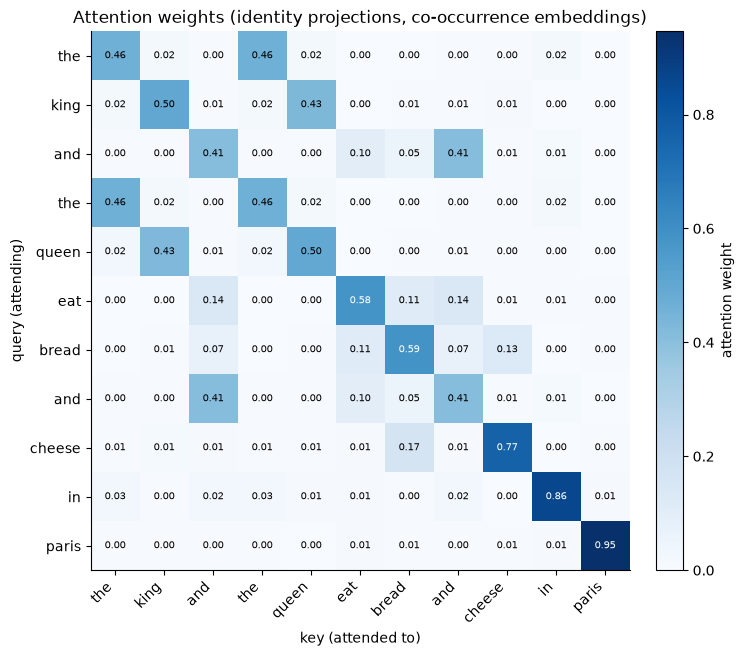

In [3]:
fig, ax = plt.subplots(figsize=(8.5, 7))
im = au.plot_attention(A, tokens, tokens, ax=ax, title="Attention weights (identity projections, co-occurrence embeddings)")
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="attention weight")
au.save_fig(fig, "05_attention_heatmap.png")
plt.show()

How to read it:

- **Diagonal**: every word is most similar to itself, so with identity projections the diagonal is bright. Real models learn projections that often look *elsewhere* (Notebook 06).
- **Blocks**: *king* ↔ *queen* attend to each other; *bread* ↔ *cheese* too — the semantic groups from Notebook 02 show up as off-diagonal bright cells.
- Repeated words (*the*, *and*) have identical rows because they have identical vectors: attention so far has **no idea of position** (fixed in Notebook 08).

### Three more views of the same numbers

Heatmaps are not the only way. Below: a bar chart for a single query, and the "bipartite lines" view popularised by tools like BertViz, where line thickness = weight.

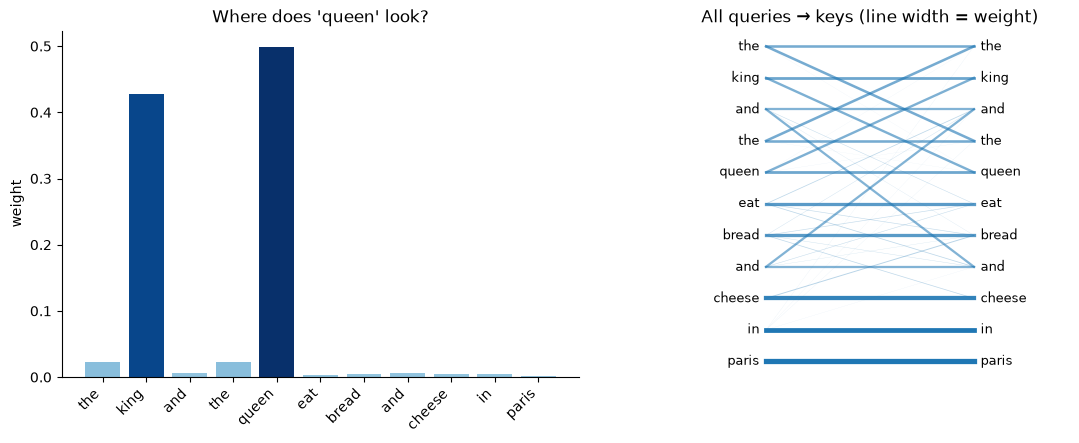

In [4]:
q_word = "queen"
qi = tokens.index(q_word)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={"width_ratios": [1.3, 1]})
axes[0].bar(range(len(tokens)), A[qi], color=plt.cm.Blues(0.4 + 0.6 * A[qi] / A[qi].max()))
axes[0].set_xticks(range(len(tokens))); axes[0].set_xticklabels(tokens, rotation=45, ha="right")
axes[0].set_ylabel("weight"); axes[0].set_title(f"Where does '{q_word}' look?")

ax = axes[1]; n = len(tokens)
for i in range(n):
    ax.text(0, -i, tokens[i], ha="right", va="center", fontsize=9)
    ax.text(1, -i, tokens[i], ha="left", va="center", fontsize=9)
    for j in range(n):
        if A[i, j] > 0.02:
            ax.plot([0.03, 0.97], [-i, -j], color="tab:blue", alpha=min(1, 0.15 + A[i, j]), lw=4 * A[i, j])
ax.set_xlim(-0.4, 1.4); ax.axis("off"); ax.set_title("All queries → keys (line width = weight)")
plt.show()

## 3. Sharp vs diffuse attention

We divided the scores by a *temperature* of 0.05. Lower temperature → sharper, more peaked rows; higher → flatter, more averaging. A handy number to summarise a row is its **entropy** (in bits): 0 means all weight on one token; $\log_2 n$ means perfectly uniform.

maximum possible entropy for 11 tokens: 3.46 bits


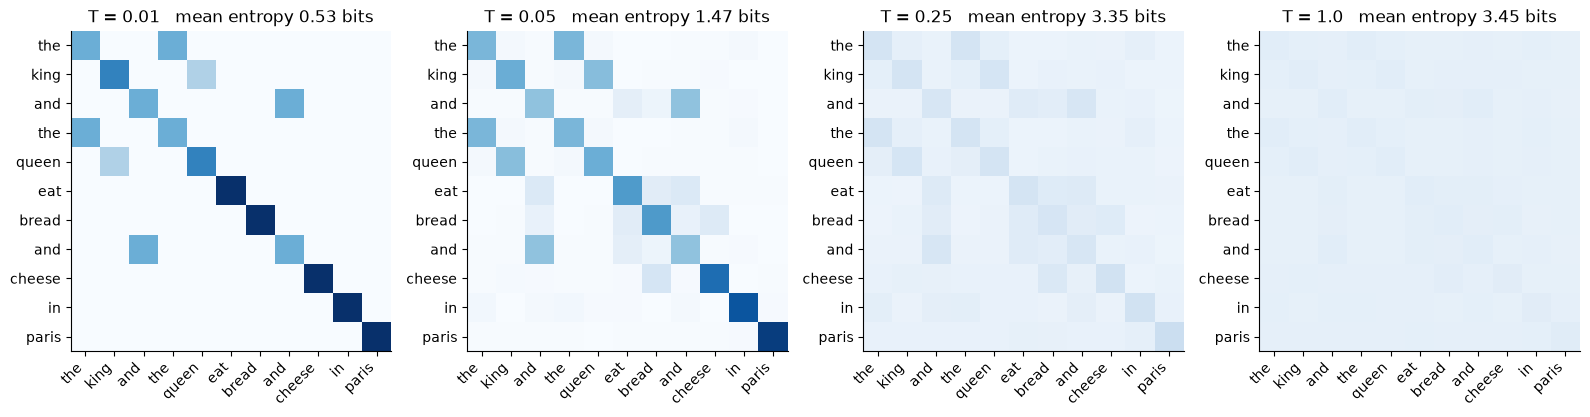

In [5]:
def row_entropy(W):
    return -(W * np.log2(W + 1e-12)).sum(-1)

temps = [0.01, 0.05, 0.25, 1.0]
fig, axes = plt.subplots(1, len(temps), figsize=(16, 4.2))
for ax, T in zip(axes, temps):
    _, AT = attend(X, T)
    au.plot_attention(AT, tokens, tokens, ax=ax, annotate=False, vmax=1,
                      title=f"T = {T}   mean entropy {row_entropy(AT).mean():.2f} bits")
    ax.set_xlabel(""); ax.set_ylabel("")
print(f"maximum possible entropy for {len(tokens)} tokens: {np.log2(len(tokens)):.2f} bits")
plt.tight_layout(); plt.show()

## 4. Learned projections change *what* counts as relevant

With $W_Q \ne W_K$, a query is compared with keys in a **different space**, so a word can attend to words that are *not* similar to itself — e.g. a verb looking for its subject. Here we just use random projections to show that the pattern changes completely; Notebook 06 shows a trained model learning a useful one.

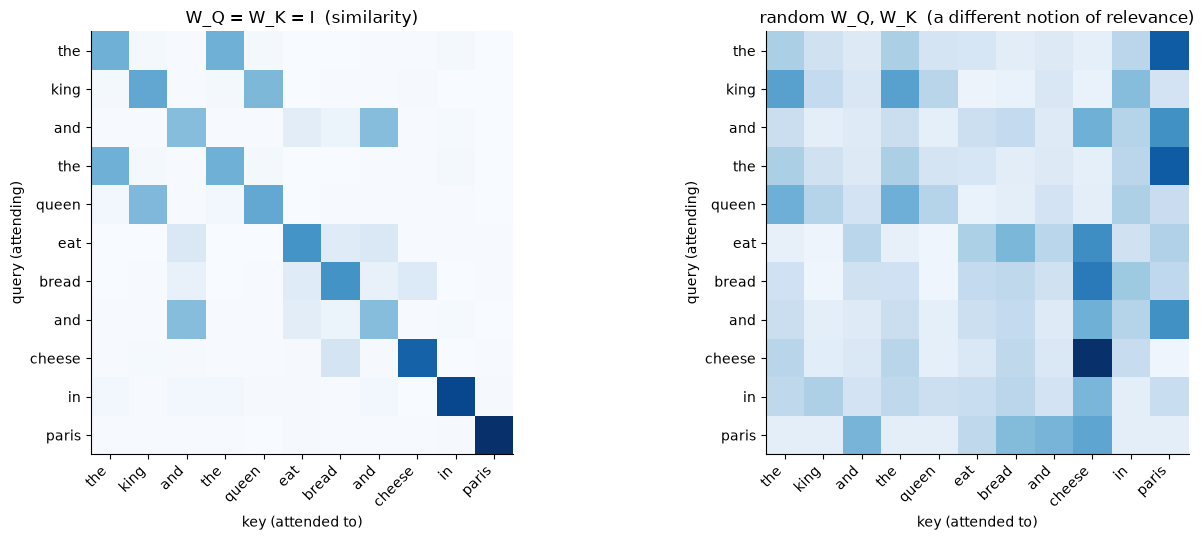

diagonal mass, identity: 6.48 | random: 1.18


In [6]:
rng = np.random.default_rng(1)
d = X.shape[1]
WQ, WK = rng.normal(size=(d, d)), rng.normal(size=(d, d))
_, A_rand = au.scaled_dot_product_attention(X @ WQ, X @ WK, X)
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
au.plot_attention(A, tokens, tokens, ax=axes[0], annotate=False, title="W_Q = W_K = I  (similarity)")
au.plot_attention(A_rand, tokens, tokens, ax=axes[1], annotate=False, title="random W_Q, W_K  (a different notion of relevance)")
plt.tight_layout(); plt.show()
print("diagonal mass, identity:", np.trace(A).round(2), "| random:", np.trace(A_rand).round(2))

## Key takeaways

- An attention heatmap has **queries on rows, keys on columns**; each row is a probability distribution.
- With identity projections attention follows **semantic similarity**; learned projections let it express other relations.
- **Temperature / scale** controls how peaked the attention is; **entropy** measures it.
- Attention weights alone ignore word order — identical words get identical rows.

> **A word of caution.** Attention heatmaps are a great teaching tool, but in large trained models they are *not* a complete explanation of a prediction (see Jain & Wallace, 2019, *"Attention is not Explanation"*, and Wiegreffe & Pinter, 2019, *"Attention is not not Explanation"*). Read them as *where information flows*, not as *why* the model decided.

### ✏️ Exercise 1

Draw the heatmap for the sentence `"the dog chases the cat and the mouse eats cheese"`. Which word does `dog` attend to most, apart from itself?

<details>
<summary><b>Show solution</b></summary>

```python
toks = au.tokenize("the dog chases the cat and the mouse eats cheese")
X2 = E[[w2i[t] for t in toks]]
_, A2 = attend(X2)
row = A2[toks.index("dog")].copy(); row[toks.index("dog")] = 0
print(toks[row.argmax()])
au.plot_attention(A2, toks, toks); plt.show()
```



</details>

### ✏️ Exercise 2

Mask the diagonal (forbid a word from attending to itself) by passing `mask=np.eye(n, dtype=bool)` and redraw the original heatmap. What does `queen` attend to now?

<details>
<summary><b>Show solution</b></summary>

```python
n = len(tokens)
_, A_nodiag = attend(X, mask=np.eye(n, dtype=bool))
print(dict(zip(tokens, A_nodiag[tokens.index("queen")].round(2))))
```



</details>

### ✏️ Exercise 3

Compute the mean row entropy of the random-projection attention `A_rand` and compare with `A`.

<details>
<summary><b>Show solution</b></summary>

```python
print(row_entropy(A).mean(), row_entropy(A_rand).mean())
```



</details>